# How People Use the App: Activity, Retention, and Products

The app offers several products: crypto exchange, a payment card, IBAN transfers, staking, crypto-backed loans, and "renting" (lending crypto for a return). This notebook answers the questions a product team asks every month:

1. How many people use the app daily and monthly, and how "sticky" is it?
2. How many come back in the following months, and does it depend on how they found the app?
3. Which products move the money, and which earn it?
4. What happened when four meme coins were listed?

**Data:** synthetic, generated by [make_data.py](make_data.py).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
tx = pd.read_csv("transactions.csv.gz", parse_dates=["time"])
users = pd.read_csv("users.csv")
done = tx[tx.status == "completed"].copy()
done["day"] = done.time.dt.normalize()
done["month"] = done.time.dt.to_period("M")
print(f"{len(tx):,} transactions by {tx.user_id.nunique():,} users")
tx.head()

389,596 transactions by 6,258 users


,tx_id,user_id,time,product,coin,amount_eur,status,fee_eur
0,1,100003,2024-01-01 01:24:00,IBAN transfer,NaN,556.76,completed,1.11
1,2,100006,2024-01-02 01:31:00,IBAN transfer,NaN,239.36,completed,0.48
2,3,100008,2024-01-02 20:20:00,exchange,SOL,430.61,completed,5.17
3,4,100003,2024-01-03 14:13:00,loan,BTC,3594.31,completed,0.00
4,5,100023,2024-01-04 02:17:00,renting,BTC,3173.65,completed,0.00


## 1. Daily and monthly active users

An active user made at least one completed transaction that day or month. **Stickiness** is DAU ÷ MAU: the share of the month's users who show up on a typical day.

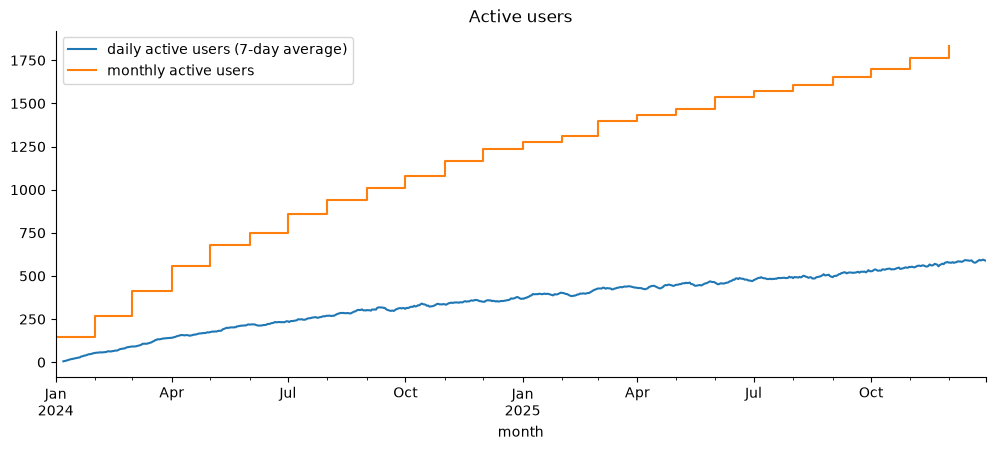

average stickiness in 2025: 31%


In [3]:
dau = done.groupby("day").user_id.nunique()
mau = done.groupby("month").user_id.nunique()
fig, ax = plt.subplots()
dau.rolling(7).mean().plot(ax=ax, label="daily active users (7-day average)")
mau.to_timestamp().plot(ax=ax, drawstyle="steps-post", label="monthly active users")
ax.set_title("Active users")
ax.legend()
plt.show()

stickiness = dau.groupby(dau.index.to_period("M")).mean() / mau
print(f"average stickiness in 2025: {stickiness[stickiness.index.year == 2025].mean():.0%}")

## 2. Retention by monthly cohort

A cohort is everyone whose first transaction was in the same month. Each cell shows what share of a cohort was active again N months later.

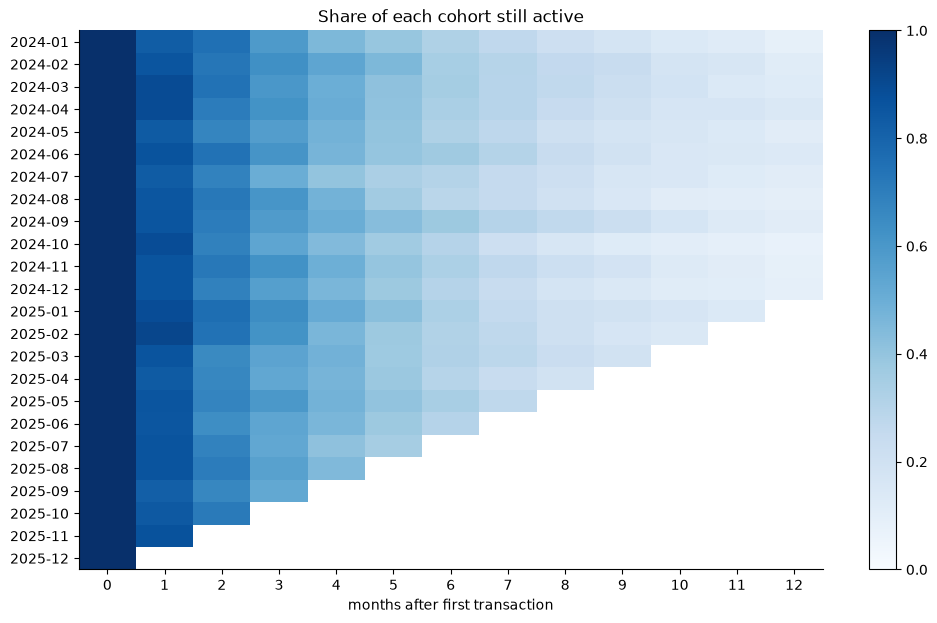

In [4]:
first_month = done.groupby("user_id").month.min().rename("cohort")
done = done.join(first_month, on="user_id")
done["months_later"] = (done.month - done.cohort).apply(lambda d: d.n)
cohorts = done.groupby(["cohort", "months_later"]).user_id.nunique().unstack()
retention = cohorts.div(cohorts[0], axis=0)

fig, ax = plt.subplots(figsize=(12, 7))
shown = retention.iloc[:, :13]
im = ax.imshow(shown, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(shown.shape[1]))
ax.set_yticks(range(len(shown)), [str(c) for c in shown.index])
ax.set_xlabel("months after first transaction")
ax.set_title("Share of each cohort still active")
plt.colorbar(im, ax=ax)
plt.show()

In [5]:
done["channel"] = done.user_id.map(users.set_index("user_id").channel)
by_channel = done.groupby(["channel", "cohort", "months_later"]).user_id.nunique().unstack()
by_channel = by_channel.div(by_channel[0], axis=0).groupby(level="channel").mean()[[1, 3, 6]]
by_channel.columns = ["after 1 month", "after 3 months", "after 6 months"]
by_channel.round(2)

,after 1 month,after 3 months,after 6 months
channel,,,
organic,0.85,0.55,0.29
paid ads,0.84,0.55,0.29
partner site,0.86,0.53,0.32
referral,0.91,0.69,0.45


Users who joined through a friend's referral stay noticeably longer than users from ads or partner sites, a strong argument for spending on referral rewards.

## 3. Which products move money, and which earn it

In [6]:
totals = done.groupby("product").agg(transactions=("tx_id", "size"), volume_eur=("amount_eur", "sum"),
                                     fees_eur=("fee_eur", "sum"), median_eur=("amount_eur", "median"))
totals["share of volume"] = totals.volume_eur / totals.volume_eur.sum()
totals["share of fees"] = totals.fees_eur / totals.fees_eur.sum()
totals.sort_values("volume_eur", ascending=False).round(2)

,transactions,volume_eur,fees_eur,median_eur,share of volume,share of fees
product,,,,,,
loan,21717,81812453.69,0.00,2521.66,0.28,0.00
renting,32869,74338023.02,0.00,1495.95,0.25,0.00
exchange,228832,59333135.38,711997.99,170.91,0.20,0.95
staking,43692,59133469.99,0.00,902.12,0.20,0.00
IBAN transfer,25079,15829676.11,31659.93,418.30,0.05,0.04
card payment,24142,1263350.41,6315.55,35.16,0.00,0.01


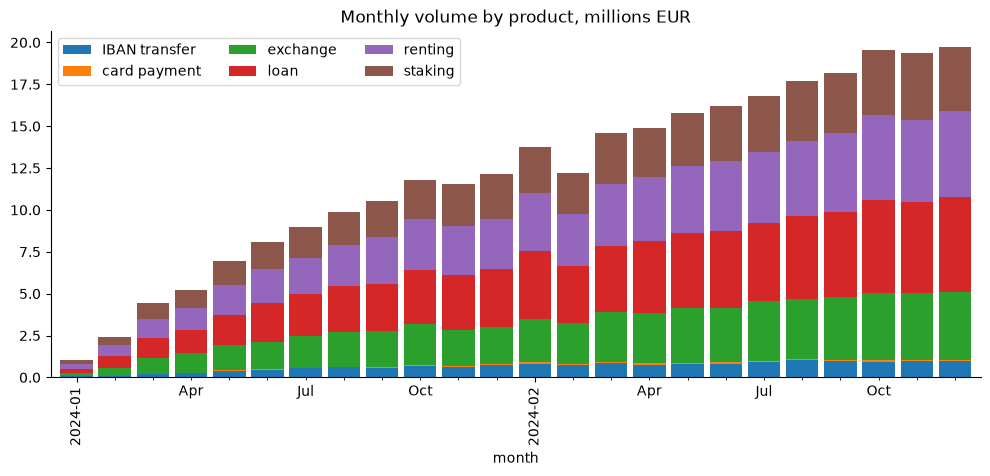

In [7]:
monthly_volume = done.pivot_table(index="month", columns="product", values="amount_eur", aggfunc="sum") / 1e6
ax = monthly_volume.plot.bar(stacked=True, width=0.85, title="Monthly volume by product, millions EUR")
ax.set_xticklabels([str(m) for m in monthly_volume.index], rotation=90)
ax.legend(ncol=3)
plt.show()

In [8]:
failed = tx.groupby("product").status.apply(lambda s: (s == "failed").mean()).sort_values(ascending=False)
failed.round(3).rename("share of failed transactions")

product
card payment     0.091
loan             0.032
staking          0.031
IBAN transfer    0.030
exchange         0.030
renting          0.029
Name: share of failed transactions, dtype: float64

## 4. Listing four meme coins

DOGE, PEPE, BONK, and FLOKI were added to the exchange in November 2024. Their share of all exchange trades, by month:

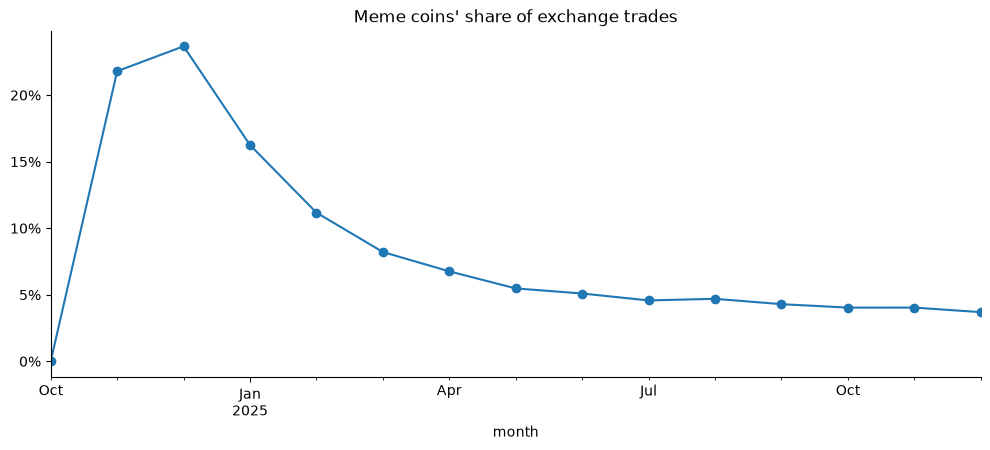

coin
DOGE     0.45
PEPE     0.30
BONK     0.15
FLOKI    0.10
Name: share of meme coin trades, dtype: float64

In [9]:
exchange = done[done["product"] == "exchange"]
meme = exchange.coin.isin(["DOGE", "PEPE", "BONK", "FLOKI"])
meme_share = meme.groupby(exchange.month).mean()
ax = meme_share.loc["2024-10":].plot(marker="o", title="Meme coins' share of exchange trades")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.show()
exchange[meme].coin.value_counts(normalize=True).round(2).rename("share of meme coin trades")

## Results

- Around 500 people use the app on a typical day of 2025 and around 1,500 in a month, so a typical day sees about a third of the month's users.
- Most users are back the month after their first transaction, but the share drops to about a third by month 6.
- Referred users keep using the app longer than those from ads or partner sites: about 69% are still active after 3 months, against about 55%.
- Loans, renting, and staking move the most money, but almost all fees come from the exchange. The card has the most failed transactions, about 9%.
- The meme coins took over a fifth of exchange trades in their first two months, then faded to about 5%: a listing brings a short burst of activity, not a lasting one.

## Tools

Python, pandas, NumPy, matplotlib